# Temporal & Multimodal Visual Intelligence
## CLIP and SigLIP frame embeddings + temporal representation analysis

**Input:** `data/processed/sequences.csv` and the JPEG frames saved by Notebook 01.  
**Encoders:** `openai/clip-vit-base-patch32` and `google/siglip-base-patch16-224`.

### Goals
1. Extract one normalized visual embedding per saved frame with each encoder.
2. Preserve the exact frame/video mapping and chronological order.
3. Analyze consecutive-frame cosine similarity.
4. Compare different videos using pooled representations.
5. Visualize per-video embedding trajectories with PCA.
6. Generate mean- and max-pooled video embeddings.

The encoders process each image independently. Temporal analysis is performed on the resulting frame embeddings; this notebook does not fine-tune either encoder or claim that either one is a temporal model.

## 0. Output directory structure

All outputs are written under `embeddings/` at the project root.

```text
embeddings/
├── embedding-store/
│   ├── clip/
│   │   ├── frame_embeddings.npy
│   │   ├── frame_manifest.csv
│   │   └── embedding_metadata.json
│   └── siglip/
│       ├── frame_embeddings.npy
│       ├── frame_manifest.csv
│       └── embedding_metadata.json
├── cosine-similarity/
│   ├── clip/ (CSV + plots/)
│   └── siglip/ (CSV + plots/)
├── sequence-similarity/
│   ├── clip/ (similarity matrix + heatmap)
│   └── siglip/ (similarity matrix + heatmap)
├── temporal-trajectory/
│   ├── clip/ (PCA coordinates + per-video plots/)
│   └── siglip/ (PCA coordinates + per-video plots/)
├── temporal-pooling/
│   ├── clip/ (mean/max pooled embeddings + manifest)
│   └── siglip/ (mean/max pooled embeddings + manifest)
└── embedding_analysis_summary.json
```

`embedding-store` contains the original frame-level vectors. The other folders contain derived analyses. No source AVI or extracted JPEG is modified.

## 1. Install dependencies

Run once in the same Python environment as Notebook 01:

```bash
pip install -U torch torchvision transformers pillow pandas numpy matplotlib scikit-learn tqdm
```

Restart the Jupyter kernel if requested.

In [ ]:
from __future__ import annotations
import json, random, warnings
from pathlib import Path
from typing import Dict, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
from transformers import AutoProcessor, CLIPModel, SiglipModel
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from transformers import (
    AutoImageProcessor,
    AutoProcessor,
    CLIPModel,
    SiglipModel,
)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.15.0
CUDA available: False


## 2. Resolve project paths and load persisted frames

This notebook reads the `sequences.csv` generated by Notebook 01. It does not re-open or decode the AVI videos. Run it from either the project root or the `notebooks/` directory. If automatic discovery fails, set `PROJECT_ROOT_OVERRIDE`.

In [8]:
PROJECT_ROOT_OVERRIDE = None
# Example: Path("/Users/your-user/Desktop/Tracking")

if PROJECT_ROOT_OVERRIDE is not None:
    PROJECT_ROOT = Path(PROJECT_ROOT_OVERRIDE).expanduser().resolve()
else:
    cwd = Path.cwd().resolve()
    candidates = [cwd, cwd.parent, cwd.parent.parent]
    PROJECT_ROOT = next(
        (p for p in candidates
         if (p / "data" / "processed" / "sequences.csv").is_file()),
        None
    )

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find data/processed/sequences.csv. Set PROJECT_ROOT_OVERRIDE."
    )

PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"
SEQUENCES_CSV = PROCESSED_ROOT / "sequences.csv"
EMBEDDINGS_ROOT = PROJECT_ROOT / "embeddings"

sequences_df = pd.read_csv(SEQUENCES_CSV)
required = {
    "video_id", "label", "frame_index",
    "frame_position", "timestamp_sec", "frame_path"
}
missing = required - set(sequences_df.columns)
if missing:
    raise ValueError(f"sequences.csv is missing columns: {sorted(missing)}")

for col in ["video_id", "label", "frame_path"]:
    sequences_df[col] = sequences_df[col].astype(str)

sequences_df["frame_index"] = pd.to_numeric(
    sequences_df["frame_index"], errors="coerce"
)
sequences_df["timestamp_sec"] = pd.to_numeric(
    sequences_df["timestamp_sec"], errors="coerce"
)
sequences_df = sequences_df.sort_values(
    ["label", "video_id", "frame_index"]
).reset_index(drop=True)

def resolve_frame_path(value):
    p = Path(value).expanduser()
    return p if p.is_absolute() else (PROJECT_ROOT / p).resolve()

sequences_df["resolved_frame_path"] = sequences_df["frame_path"].map(
    resolve_frame_path
)
missing_frames = sequences_df[
    ~sequences_df["resolved_frame_path"].map(lambda p: p.is_file())
]

print("Project root:", PROJECT_ROOT)
print("Saved frame records:", len(sequences_df))
print("Videos:", sequences_df[["label", "video_id"]].drop_duplicates().shape[0])
print("Classes:", sequences_df["label"].nunique())
print("Missing JPEGs:", len(missing_frames))
if len(missing_frames):
    display(missing_frames.head())
    raise FileNotFoundError("Some saved frames referenced by sequences.csv are missing.")

display(sequences_df.head())

Project root: /Users/vanshikaarora/Desktop/Tracking
Saved frame records: 6662
Videos: 950
Classes: 9
Missing JPEGs: 0


,video_id,label,frame_index,frame_position,timestamp_sec,frame_path,resolved_frame_path
0,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,0,0,0.000000,/Users/vanshikaarora/Desktop/Tracking/data/pro...,/Users/vanshikaarora/Desktop/Tracking/data/pro...
1,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,58,1,1.933333,/Users/vanshikaarora/Desktop/Tracking/data/pro...,/Users/vanshikaarora/Desktop/Tracking/data/pro...
2,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,116,2,3.866667,/Users/vanshikaarora/Desktop/Tracking/data/pro...,/Users/vanshikaarora/Desktop/Tracking/data/pro...
3,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,174,3,5.800000,/Users/vanshikaarora/Desktop/Tracking/data/pro...,/Users/vanshikaarora/Desktop/Tracking/data/pro...
4,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,233,4,7.766667,/Users/vanshikaarora/Desktop/Tracking/data/pro...,/Users/vanshikaarora/Desktop/Tracking/data/pro...


## 3. Create the output folders

Safe to rerun. Folder names use lowercase model identifiers `clip` and `siglip`.

In [9]:
ANALYSIS_NAMES = [
    "embedding-store", "cosine-similarity",
    "sequence-similarity", "temporal-trajectory",
    "temporal-pooling"
]
MODEL_NAMES = ["clip", "siglip"]

for analysis in ANALYSIS_NAMES:
    for model_name in MODEL_NAMES:
        (EMBEDDINGS_ROOT / analysis / model_name).mkdir(
            parents=True, exist_ok=True
        )

for analysis in ["cosine-similarity", "sequence-similarity", "temporal-trajectory"]:
    for model_name in MODEL_NAMES:
        (EMBEDDINGS_ROOT / analysis / model_name / "plots").mkdir(
            parents=True, exist_ok=True
        )

print("Output root:", EMBEDDINGS_ROOT)

Output root: /Users/vanshikaarora/Desktop/Tracking/embeddings


## 4. Verify sequence ordering and frame counts

The frame manifest is sorted by label, video ID, and original frame index. Check that each video has strictly increasing indices before embedding extraction.

In [10]:
sequence_rows = []
for (label, video_id), group in sequences_df.groupby(
    ["label", "video_id"], sort=False
):
    idx = group["frame_index"].dropna().astype(int).tolist()
    sequence_rows.append({
        "label": label,
        "video_id": video_id,
        "num_frames": len(idx),
        "strictly_increasing": all(a < b for a, b in zip(idx, idx[1:])),
        "duplicate_indices": len(idx) != len(set(idx))
    })

sequence_checks = pd.DataFrame(sequence_rows)
print("Videos:", len(sequence_checks))
print("Ordered sequences:", int(sequence_checks["strictly_increasing"].sum()))
print("Sequences with duplicate indices:", int(sequence_checks["duplicate_indices"].sum()))
display(sequence_checks.head())
display(sequence_checks["num_frames"].describe())
if not sequence_checks["strictly_increasing"].all():
    warnings.warn("Some sequences do not have strictly increasing frame indices.")

Videos: 950
Ordered sequences: 950
Sequences with duplicate indices: 0


,label,video_id,num_frames,strictly_increasing,duplicate_indices
0,brush_hair,April_09_brush_hair_u_nm_np1_ba_goo_0,7,True,False
1,brush_hair,April_09_brush_hair_u_nm_np1_ba_goo_1,7,True,False
2,brush_hair,April_09_brush_hair_u_nm_np1_ba_goo_2,7,True,False
3,brush_hair,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,7,True,False
4,brush_hair,Aussie_Brunette_Brushing_Hair_II_brush_hair_u_...,7,True,False


count    950.000000
mean       7.012632
std        0.111737
min        7.000000
25%        7.000000
50%        7.000000
75%        7.000000
max        8.000000
Name: num_frames, dtype: float64

## 5. Configure device and inference settings

The notebook selects CUDA, then Apple MPS, then CPU. If MPS causes an unsupported-operation error in your environment, set `DEVICE_OVERRIDE = "cpu"` and rerun the extraction cell for the affected model.

In [11]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

DEVICE_OVERRIDE = None  # Optional: "cpu", "mps", or "cuda"
if DEVICE_OVERRIDE is not None:
    DEVICE = torch.device(DEVICE_OVERRIDE)

BATCH_SIZE = 32
FORCE_REEXTRACT = False

print("Device:", DEVICE)
print("Batch size:", BATCH_SIZE)

Device: mps
Batch size: 32


## 6. Shared extraction utilities

Both encoders expose `get_image_features`. The resulting projected image vectors are L2-normalized. This makes cosine similarity equal to the dot product of two normalized vectors (up to floating-point precision).

CLIP and SigLIP may have different embedding dimensions. Do not compare their raw vectors directly.

In [12]:
def load_rgb(path):
    with Image.open(path) as image:
        return image.convert("RGB")

def l2_normalize(x, eps=1e-12):
    norms = np.linalg.norm(x, axis=1, keepdims=True)
    return x / np.maximum(norms, eps)

def build_frame_manifest(df):
    cols = [
        "video_id", "label", "frame_index",
        "frame_position", "timestamp_sec", "frame_path"
    ]
    result = df[cols].copy().reset_index(drop=True)
    result.insert(0, "embedding_row", np.arange(len(result)))
    return result

frame_manifest = build_frame_manifest(sequences_df)
display(frame_manifest.head())

,embedding_row,video_id,label,frame_index,frame_position,timestamp_sec,frame_path
0,0,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,0,0,0.000000,/Users/vanshikaarora/Desktop/Tracking/data/pro...
1,1,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,58,1,1.933333,/Users/vanshikaarora/Desktop/Tracking/data/pro...
2,2,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,116,2,3.866667,/Users/vanshikaarora/Desktop/Tracking/data/pro...
3,3,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,174,3,5.800000,/Users/vanshikaarora/Desktop/Tracking/data/pro...
4,4,April_09_brush_hair_u_nm_np1_ba_goo_0,brush_hair,233,4,7.766667,/Users/vanshikaarora/Desktop/Tracking/data/pro...


## 7. Generic extraction and cache function

The saved manifest maps each embedding row back to its source frame. Existing cached vectors are reused only if their frame paths and video IDs match the current input manifest. Set `FORCE_REEXTRACT=True` to deliberately regenerate embeddings.

In [24]:
def extract_model_embeddings(model_id, model_kind, output_dir,
                             batch_size=BATCH_SIZE, force=FORCE_REEXTRACT):
    output_dir.mkdir(parents=True, exist_ok=True)
    emb_path = output_dir / "frame_embeddings.npy"
    manifest_path = output_dir / "frame_manifest.csv"
    metadata_path = output_dir / "embedding_metadata.json"

    expected = build_frame_manifest(sequences_df)

    if (not force and emb_path.exists() and manifest_path.exists()
            and metadata_path.exists()):
        saved = pd.read_csv(manifest_path)
        same_inputs = (
            len(saved) == len(expected)
            and saved["frame_path"].astype(str).equals(
                expected["frame_path"].astype(str))
            and saved["video_id"].astype(str).equals(
                expected["video_id"].astype(str))
            and saved["label"].astype(str).equals(
                expected["label"].astype(str))
            and saved["frame_index"].equals(expected["frame_index"])
        )
        if same_inputs:
            cached = np.load(emb_path)
            print(f"Using cached {model_kind} embeddings:", cached.shape)
            return cached, saved, json.loads(metadata_path.read_text())

    print("Loading:", model_id)
    processor = AutoImageProcessor.from_pretrained(model_id)
    if model_kind == "clip":
        model = CLIPModel.from_pretrained(model_id)
    elif model_kind == "siglip":
        model = SiglipModel.from_pretrained(model_id)
    else:
        raise ValueError("model_kind must be clip or siglip")

    model.to(DEVICE)
    model.eval()
    frame_paths = expected["frame_path"].astype(str).tolist()
    batches = []

    with torch.inference_mode():
        for start in tqdm(range(0, len(frame_paths), batch_size),
                          desc=f"{model_kind.upper()} frame embeddings"):
            paths = frame_paths[start:start + batch_size]
            images = [load_rgb(p) for p in paths]
            inputs = processor(images=images, return_tensors="pt")
            pixel_values = inputs["pixel_values"].to(DEVICE)
            features = model.get_image_features(pixel_values=pixel_values)
            # Handle different Transformers API return formats.
            if hasattr(features, "pooler_output"):
                features = features.pooler_output
            elif not isinstance(features, torch.Tensor):
                raise TypeError(
        f"Unexpected feature output type: {type(features)}"
    )

            batches.append(features.detach().float().cpu().numpy())

    vectors = np.concatenate(batches, axis=0).astype(np.float32)
    vectors = l2_normalize(vectors)

    expected.to_csv(manifest_path, index=False)
    np.save(emb_path, vectors)

    metadata = {
        "model_id": model_id,
        "model_kind": model_kind,
        "num_frames": int(vectors.shape[0]),
        "embedding_dimension": int(vectors.shape[1]),
        "l2_normalized": True,
        "device": str(DEVICE),
        "batch_size": int(batch_size),
        "source_manifest": str(SEQUENCES_CSV)
    }
    metadata_path.write_text(json.dumps(metadata, indent=2))

    del model, processor
    if DEVICE.type == "mps":
        try:
            torch.mps.empty_cache()
        except Exception:
            pass
    elif DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    print(f"Saved {model_kind.upper()} vectors:", vectors.shape)
    return vectors, expected, metadata

## 8. Extract CLIP embeddings

Model: `openai/clip-vit-base-patch32`.

Expected artifact directory: `embeddings/embedding-store/clip/`.

In [16]:
CLIP_MODEL_ID = "openai/clip-vit-base-patch32"
clip_dir = EMBEDDINGS_ROOT / "embedding-store" / "clip"

clip_embeddings, clip_manifest, clip_metadata = extract_model_embeddings(
    CLIP_MODEL_ID, "clip", clip_dir
)
print("CLIP:", clip_embeddings.shape)

Loading: openai/clip-vit-base-patch32


CLIP frame embeddings: 100%|██████████| 209/209 [01:51<00:00,  1.87it/s]


Saved CLIP vectors: (6662, 512)
CLIP: (6662, 512)


## 9. Extract SigLIP embeddings

Model: `google/siglip-base-patch16-224`.

Expected artifact directory: `embeddings/embedding-store/siglip/`. The same input frames and row ordering are used as for CLIP.

In [25]:
import sentencepiece
print("SentencePiece version:", sentencepiece.__version__)
import sys
import importlib.util
import sentencepiece
from transformers import (
    AutoImageProcessor,
    AutoProcessor,
    CLIPModel,
    SiglipModel,
)

print("Python executable:", sys.executable)
print("SentencePiece version:", sentencepiece.__version__)
print("SentencePiece location:", sentencepiece.__file__)
print("Transformers version:", transformers.__version__)
print("SentencePiece discoverable:", importlib.util.find_spec("sentencepiece") is not None)

SentencePiece version: 0.2.2
Python executable: /Users/vanshikaarora/Desktop/Tracking/venv/bin/python
SentencePiece version: 0.2.2
SentencePiece location: /Users/vanshikaarora/Desktop/Tracking/venv/lib/python3.11/site-packages/sentencepiece/__init__.py
Transformers version: 5.22.1
SentencePiece discoverable: True


In [26]:
SIGLIP_MODEL_ID = "google/siglip-base-patch16-224"
siglip_dir = EMBEDDINGS_ROOT / "embedding-store" / "siglip"

siglip_embeddings, siglip_manifest, siglip_metadata = extract_model_embeddings(
    SIGLIP_MODEL_ID, "siglip", siglip_dir
)
print("SigLIP:", siglip_embeddings.shape)

Loading: google/siglip-base-patch16-224


SIGLIP frame embeddings: 100%|██████████| 209/209 [06:10<00:00,  1.77s/it]


Saved SIGLIP vectors: (6662, 768)
SigLIP: (6662, 768)


## 10. Validate the embedding stores

Check row alignment, finite values, and L2 norms. Each embedding row must correspond to one row in its frame manifest.

In [27]:
def integrity_row(name, vectors, manifest):
    norms = np.linalg.norm(vectors, axis=1)
    return {
        "model": name,
        "shape": str(vectors.shape),
        "manifest_rows": len(manifest),
        "all_finite": bool(np.isfinite(vectors).all()),
        "mean_l2_norm": float(norms.mean()),
        "min_l2_norm": float(norms.min()),
        "max_l2_norm": float(norms.max()),
        "row_count_matches": len(vectors) == len(manifest)
    }

integrity = pd.DataFrame([
    integrity_row("CLIP", clip_embeddings, clip_manifest),
    integrity_row("SigLIP", siglip_embeddings, siglip_manifest)
])
display(integrity)

if not integrity["all_finite"].all() or not integrity["row_count_matches"].all():
    raise ValueError("Embedding integrity check failed.")

,model,shape,manifest_rows,all_finite,mean_l2_norm,min_l2_norm,max_l2_norm,row_count_matches
0,CLIP,"(6662, 512)",6662,True,1.0,1.0,1.0,True
1,SigLIP,"(6662, 768)",6662,True,1.0,1.0,1.0,True


## 11. Group embedding rows by video

All temporal calculations use the saved manifest to recover each video's frame rows in ascending original frame-index order.

In [28]:
def video_groups(manifest):
    groups = {}
    for (label, video_id), group in manifest.groupby(
        ["label", "video_id"], sort=False
    ):
        ordered = group.sort_values("frame_index")
        groups[(str(label), str(video_id))] = (
            ordered["embedding_row"].to_numpy(dtype=int)
        )
    return groups

clip_groups = video_groups(clip_manifest)
siglip_groups = video_groups(siglip_manifest)
print("CLIP sequences:", len(clip_groups))
print("SigLIP sequences:", len(siglip_groups))

CLIP sequences: 950
SigLIP sequences: 950


## 12. Analysis A — cosine similarity between consecutive frames

For each video, calculate the cosine similarity of each adjacent pair:

\[
s_t = \frac{E_t \cdot E_{t+1}}{\|E_t\|\|E_{t+1}\|}
\]

Because the frame vectors are L2-normalized, the dot product gives cosine similarity.

Higher similarity means adjacent frames have more similar encoded visual content. Lower similarity may reflect pose, object, viewpoint, lighting, or scene changes. It is **not** a direct measurement of physical motion.

In [29]:
def consecutive_similarity(vectors, manifest, model_name):
    rows = []
    for (label, video_id), indices in video_groups(manifest).items():
        if len(indices) < 2:
            continue
        seq = vectors[indices]
        sims = np.sum(seq[:-1] * seq[1:], axis=1)
        meta = manifest.iloc[indices].sort_values("frame_index").reset_index(drop=True)

        for i, sim in enumerate(sims):
            rows.append({
                "model": model_name,
                "label": label,
                "video_id": video_id,
                "frame_index_t": int(meta.loc[i, "frame_index"]),
                "frame_index_t1": int(meta.loc[i+1, "frame_index"]),
                "timestamp_t": meta.loc[i, "timestamp_sec"],
                "timestamp_t1": meta.loc[i+1, "timestamp_sec"],
                "cosine_similarity": float(sim),
                "cosine_distance": float(1.0 - sim)
            })
    return pd.DataFrame(rows)

clip_consecutive = consecutive_similarity(
    clip_embeddings, clip_manifest, "CLIP"
)
siglip_consecutive = consecutive_similarity(
    siglip_embeddings, siglip_manifest, "SigLIP"
)

(EMBEDDINGS_ROOT / "cosine-similarity" / "clip"
 / "consecutive_frame_similarity.csv").parent.mkdir(parents=True, exist_ok=True)
clip_consecutive.to_csv(
    EMBEDDINGS_ROOT / "cosine-similarity" / "clip"
    / "consecutive_frame_similarity.csv", index=False
)
siglip_consecutive.to_csv(
    EMBEDDINGS_ROOT / "cosine-similarity" / "siglip"
    / "consecutive_frame_similarity.csv", index=False
)

print("CLIP adjacent pairs:", len(clip_consecutive))
print("SigLIP adjacent pairs:", len(siglip_consecutive))
display(clip_consecutive.head())

CLIP adjacent pairs: 5712
SigLIP adjacent pairs: 5712


,model,label,video_id,frame_index_t,frame_index_t1,timestamp_t,timestamp_t1,cosine_similarity,cosine_distance
0,CLIP,brush_hair,April_09_brush_hair_u_nm_np1_ba_goo_0,0,58,0.000000,1.933333,0.881142,0.118858
1,CLIP,brush_hair,April_09_brush_hair_u_nm_np1_ba_goo_0,58,116,1.933333,3.866667,0.949758,0.050242
2,CLIP,brush_hair,April_09_brush_hair_u_nm_np1_ba_goo_0,116,174,3.866667,5.800000,0.953963,0.046037
3,CLIP,brush_hair,April_09_brush_hair_u_nm_np1_ba_goo_0,174,233,5.800000,7.766667,0.946954,0.053046
4,CLIP,brush_hair,April_09_brush_hair_u_nm_np1_ba_goo_0,233,291,7.766667,9.700000,0.949308,0.050692


## 13. Visualize consecutive-frame similarity

The line plot shows how adjacent-frame similarity changes within one example video. The histogram compares the distribution across all videos for each encoder.

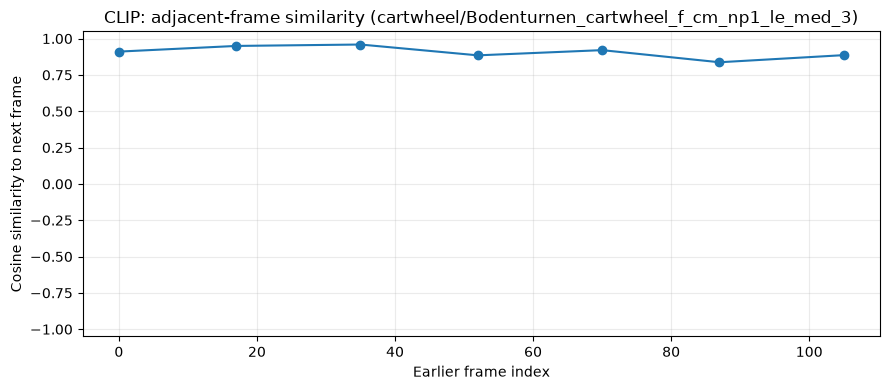

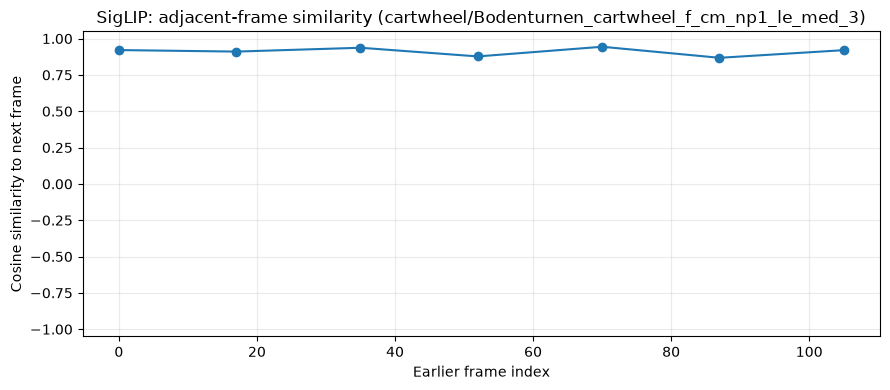

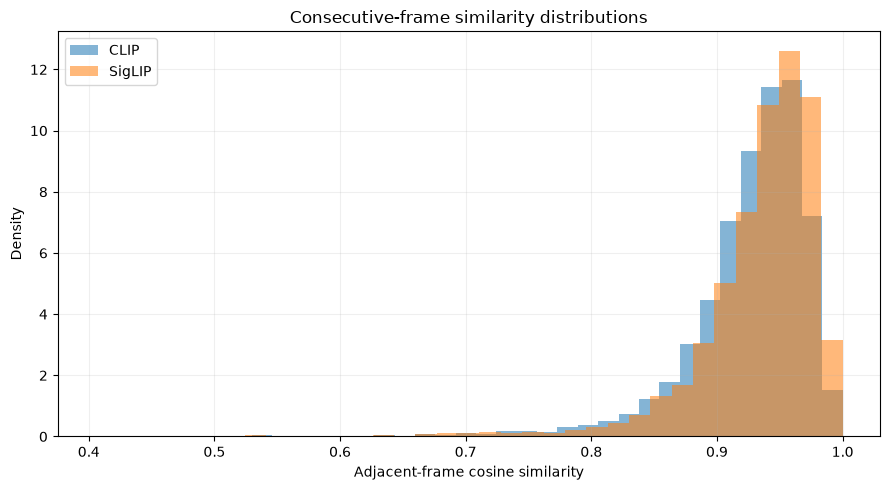

In [30]:
def plot_example_similarity(df, model_name, output_dir):
    if df.empty:
        print("No consecutive pairs:", model_name)
        return
    counts = df.groupby(["label", "video_id"]).size()
    label, video_id = counts.sort_values(ascending=False).index[0]
    sample = df[
        (df["label"] == label) & (df["video_id"] == video_id)
    ].sort_values("frame_index_t")

    plt.figure(figsize=(9, 4))
    plt.plot(sample["frame_index_t"], sample["cosine_similarity"], marker="o")
    plt.ylim(-1.05, 1.05)
    plt.xlabel("Earlier frame index")
    plt.ylabel("Cosine similarity to next frame")
    plt.title(f"{model_name}: adjacent-frame similarity ({label}/{video_id})")
    plt.grid(alpha=.25)
    plt.tight_layout()
    plt.savefig(output_dir / "example_consecutive_similarity.png", dpi=160)
    plt.show()

plot_example_similarity(
    clip_consecutive, "CLIP",
    EMBEDDINGS_ROOT / "cosine-similarity" / "clip" / "plots"
)
plot_example_similarity(
    siglip_consecutive, "SigLIP",
    EMBEDDINGS_ROOT / "cosine-similarity" / "siglip" / "plots"
)

plt.figure(figsize=(9, 5))
plt.hist(clip_consecutive["cosine_similarity"].dropna(),
         bins=35, density=True, alpha=.55, label="CLIP")
plt.hist(siglip_consecutive["cosine_similarity"].dropna(),
         bins=35, density=True, alpha=.55, label="SigLIP")
plt.xlabel("Adjacent-frame cosine similarity")
plt.ylabel("Density")
plt.title("Consecutive-frame similarity distributions")
plt.legend()
plt.grid(alpha=.2)
plt.tight_layout()
plt.savefig(
    EMBEDDINGS_ROOT / "cosine-similarity"
    / "consecutive_similarity_distribution_comparison.png",
    dpi=160
)
plt.show()

## 14. Analysis B — similarity between different video sequences

First mean-pool each video's frame embeddings into one video-level vector. Then calculate cosine similarity between every pair of video vectors.

This explores whether videos from the same action class occupy similar regions of the pretrained representation space. Mean pooling ignores frame order, so this is a sequence-level appearance summary, not a temporal model.

In [31]:
def pool_by_video(vectors, manifest, method="mean"):
    pooled, records = [], []
    for (label, video_id), indices in video_groups(manifest).items():
        seq = vectors[indices]
        if method == "mean":
            v = seq.mean(axis=0)
        elif method == "max":
            v = seq.max(axis=0)
        else:
            raise ValueError("method must be mean or max")
        v = v / max(float(np.linalg.norm(v)), 1e-12)
        pooled.append(v.astype(np.float32))
        records.append({
            "label": label, "video_id": video_id, "num_frames": len(indices)
        })
    return np.vstack(pooled), pd.DataFrame(records)

clip_video_mean, clip_video_manifest = pool_by_video(
    clip_embeddings, clip_manifest, "mean"
)
siglip_video_mean, siglip_video_manifest = pool_by_video(
    siglip_embeddings, siglip_manifest, "mean"
)

clip_video_sim = cosine_similarity(clip_video_mean)
siglip_video_sim = cosine_similarity(siglip_video_mean)

for name, matrix, vmanifest in [
    ("clip", clip_video_sim, clip_video_manifest),
    ("siglip", siglip_video_sim, siglip_video_manifest)
]:
    outdir = EMBEDDINGS_ROOT / "sequence-similarity" / name
    np.save(outdir / "video_similarity_matrix.npy", matrix)
    vmanifest.to_csv(outdir / "video_manifest.csv", index=False)
    names = [f"{r.label}/{r.video_id}" for r in vmanifest.itertuples()]
    pd.DataFrame(matrix, index=names, columns=names).to_csv(
        outdir / "video_similarity.csv"
    )

print("CLIP video matrix:", clip_video_sim.shape)
print("SigLIP video matrix:", siglip_video_sim.shape)

CLIP video matrix: (950, 950)
SigLIP video matrix: (950, 950)


## 15. Visualize video-to-video similarity matrices

Rows and columns are videos ordered by class. Brighter/higher-valued cells indicate greater cosine similarity. Class blocks may indicate shared visual appearance, but background and scene similarity can also contribute.

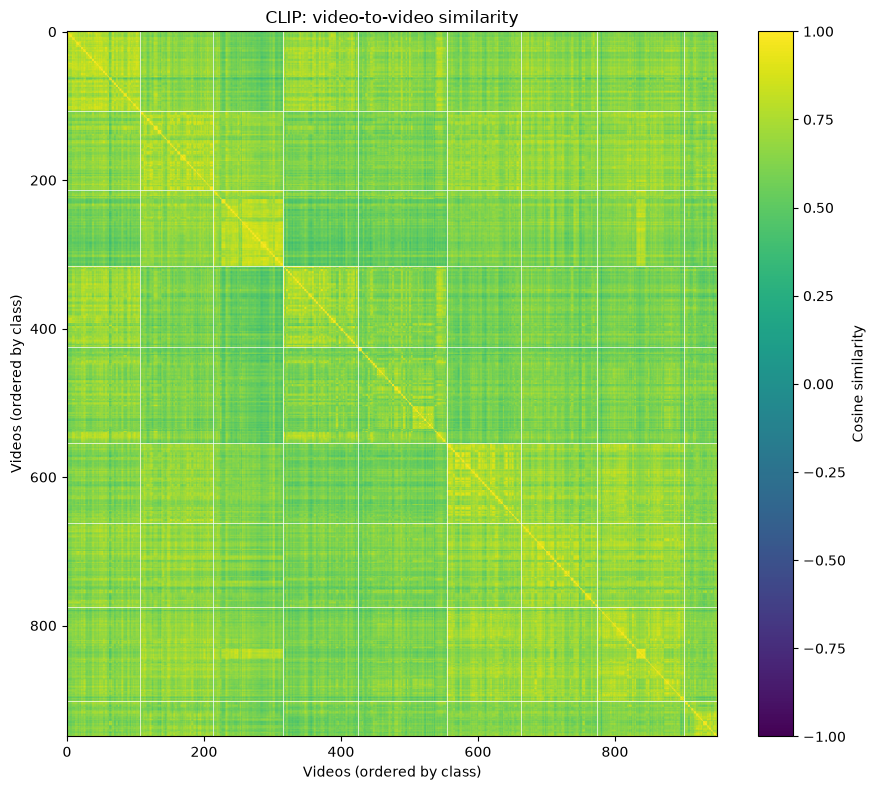

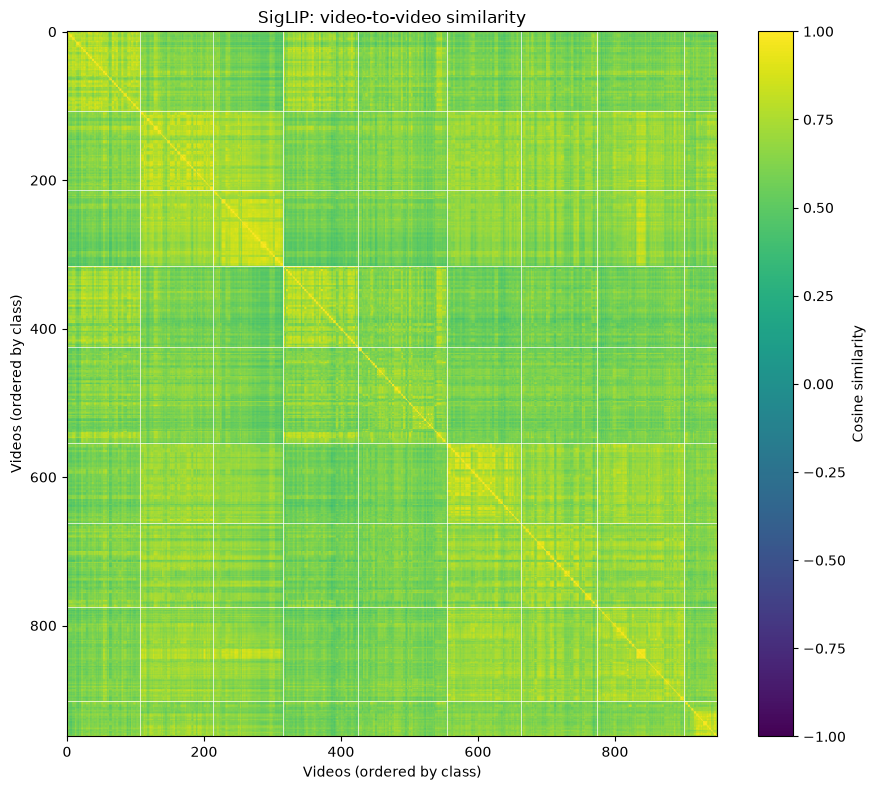

In [32]:
def plot_video_matrix(matrix, manifest, model_name, output_path):
    order = np.lexsort((
        manifest["video_id"].astype(str).to_numpy(),
        manifest["label"].astype(str).to_numpy()
    ))
    ordered = matrix[np.ix_(order, order)]
    ordered_manifest = manifest.iloc[order].reset_index(drop=True)

    plt.figure(figsize=(9, 8))
    plt.imshow(ordered, vmin=-1, vmax=1, aspect="auto")
    plt.colorbar(label="Cosine similarity")
    plt.title(f"{model_name}: video-to-video similarity")
    plt.xlabel("Videos (ordered by class)")
    plt.ylabel("Videos (ordered by class)")

    labels = ordered_manifest["label"].tolist()
    for i in range(1, len(labels)):
        if labels[i] != labels[i-1]:
            plt.axhline(i - .5, color="white", linewidth=.5)
            plt.axvline(i - .5, color="white", linewidth=.5)

    plt.tight_layout()
    plt.savefig(output_path, dpi=160)
    plt.show()

plot_video_matrix(
    clip_video_sim, clip_video_manifest, "CLIP",
    EMBEDDINGS_ROOT / "sequence-similarity" / "clip"
    / "plots" / "video_similarity_matrix.png"
)
plot_video_matrix(
    siglip_video_sim, siglip_video_manifest, "SigLIP",
    EMBEDDINGS_ROOT / "sequence-similarity" / "siglip"
    / "plots" / "video_similarity_matrix.png"
)

## 16. Analysis C — temporal embedding trajectory

A trajectory connects the frame embeddings from one video in chronological order. PCA reduces the high-dimensional embeddings to two dimensions for visualization.

A large step in the plot means the encoded representation changed between observations in the projected space. It is not a literal physical motion path, and PCA may discard information.

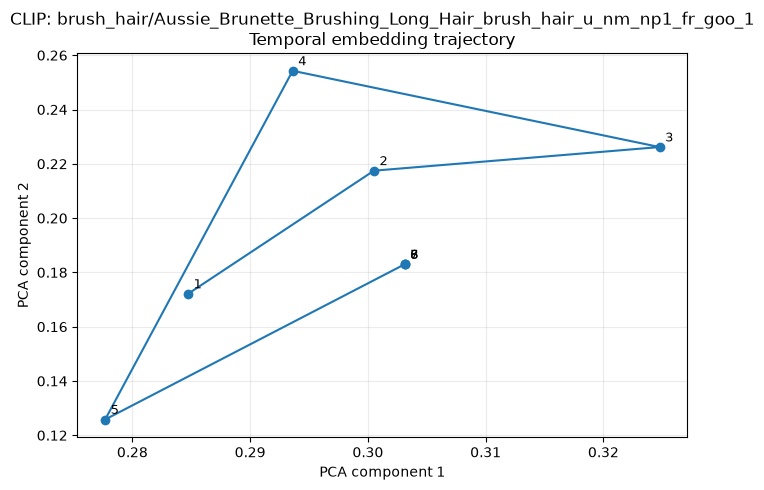

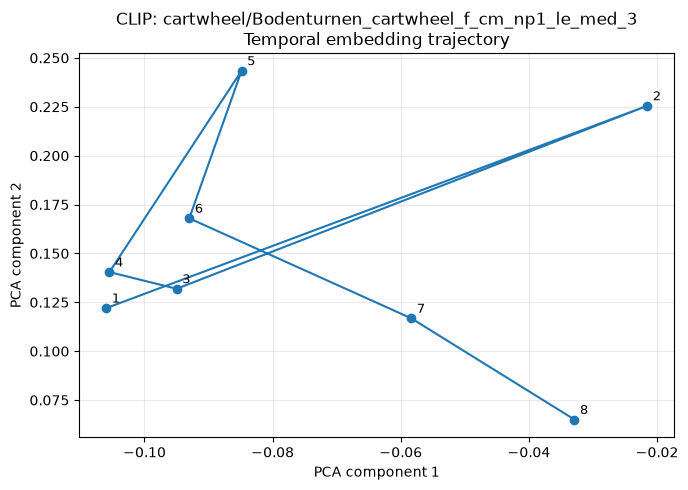

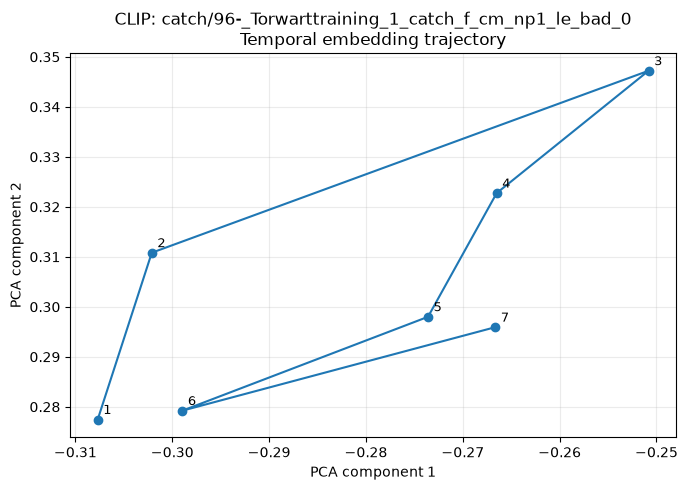

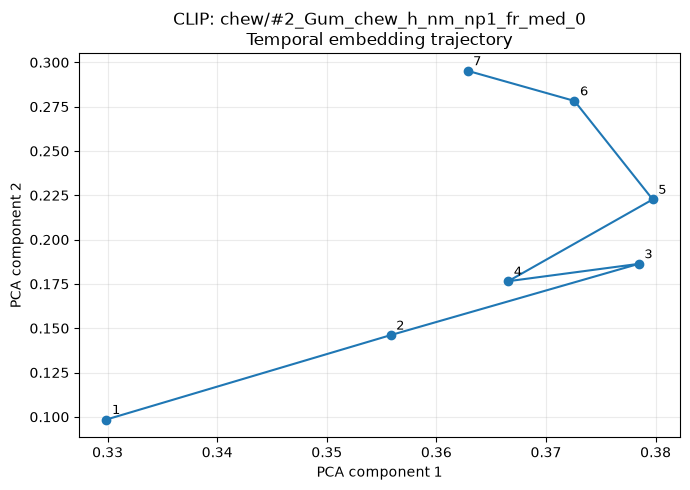

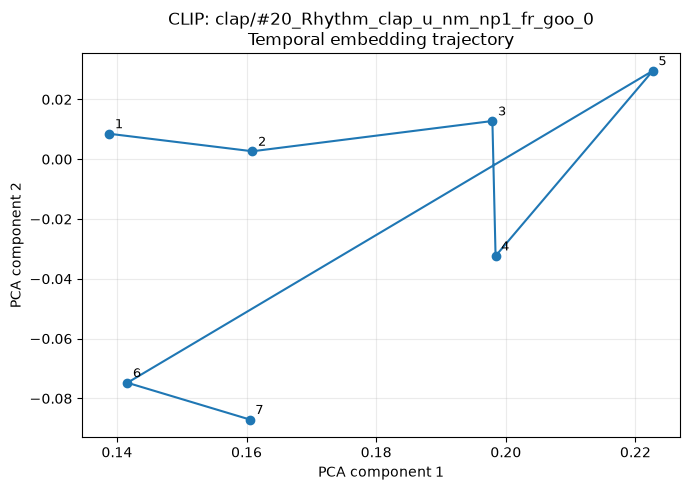

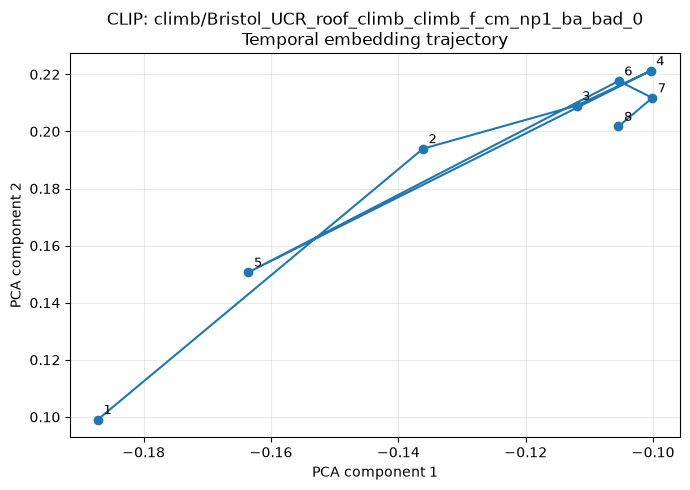

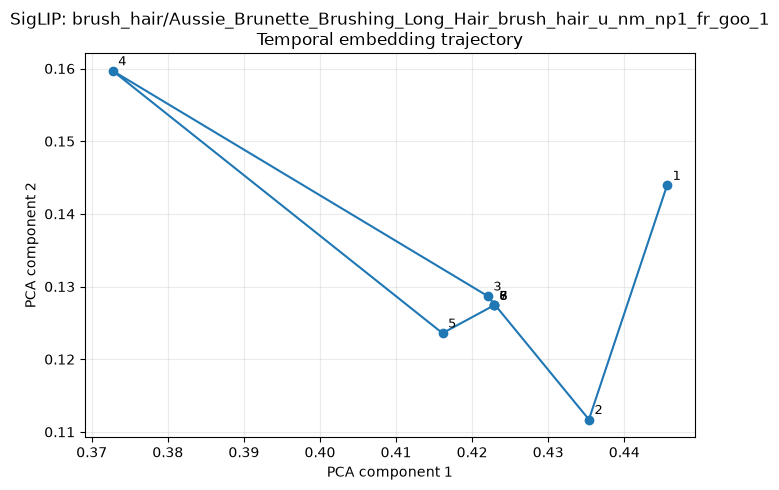

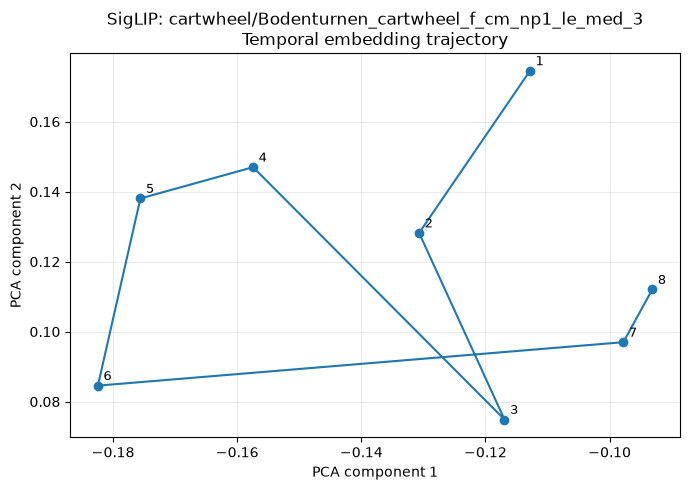

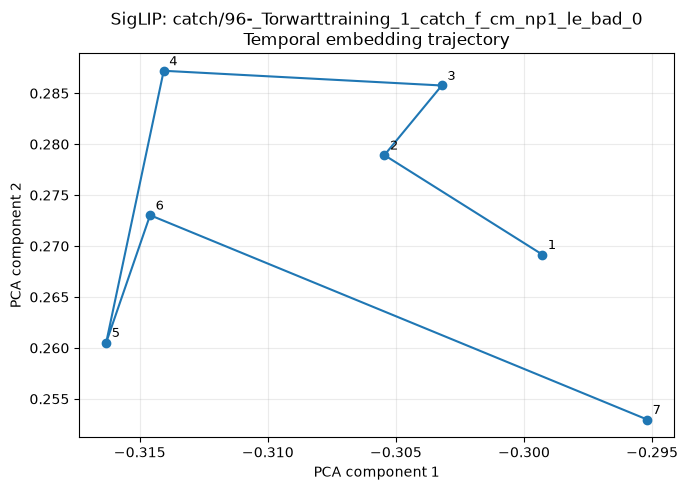

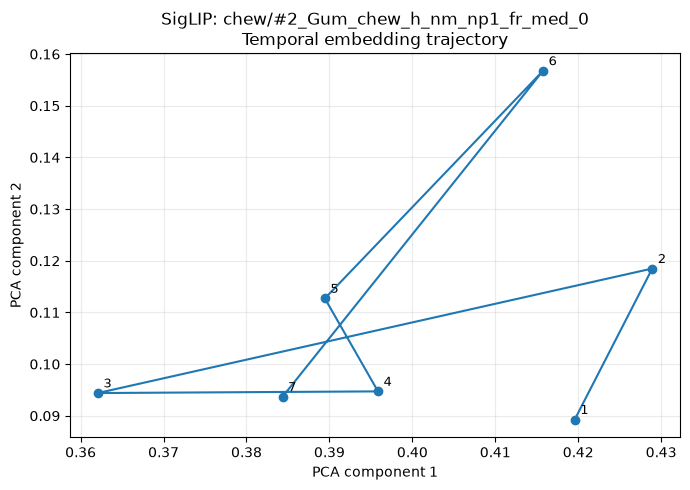

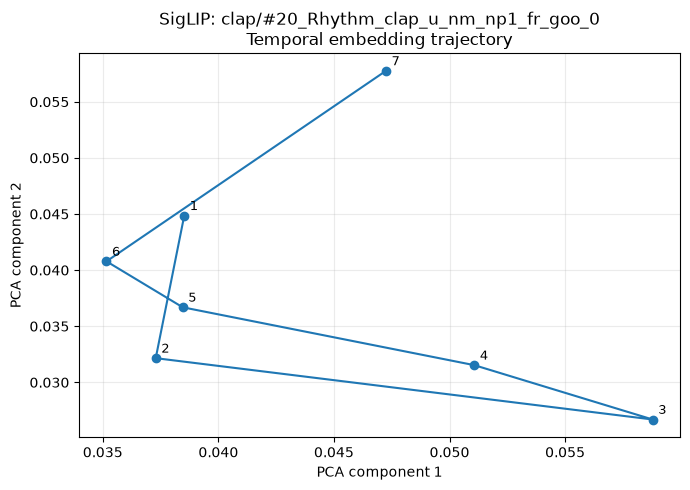

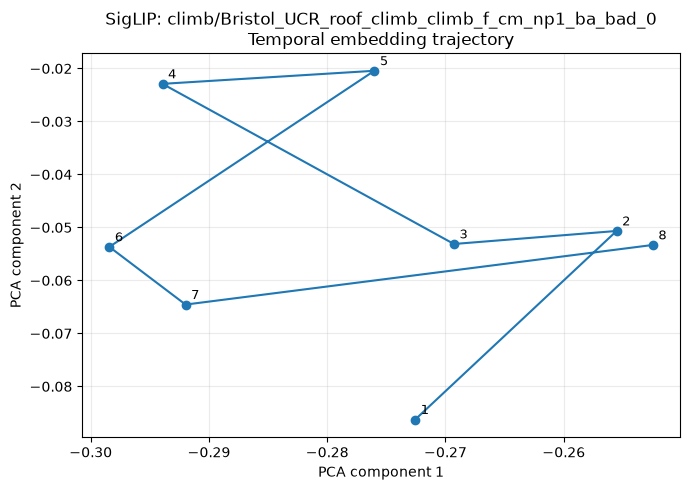

CLIP 2D PCA variance explained: 0.1702
SigLIP 2D PCA variance explained: 0.1831


In [41]:
def plot_trajectories(
    vectors,
    manifest,
    model_name,
    output_dir,
    max_videos=6
):
    # Reduce the full frame embeddings to 2D.
    pca = PCA(n_components=2, random_state=SEED)
    projected = pca.fit_transform(vectors)

    explained = float(pca.explained_variance_ratio_.sum())

    groups = video_groups(manifest)

    # Select one representative video per class.
    # Choose the video with the most sampled frames.
    class_representatives = []

    for label in sorted(manifest["label"].unique()):

        class_videos = [
            (key, indices)
            for key, indices in groups.items()
            if key[0] == label
        ]

        if not class_videos:
            continue

        representative = max(
            class_videos,
            key=lambda item: len(item[1])
        )

        class_representatives.append(representative)

    # Limit the number of plotted videos.
    chosen = class_representatives[:max_videos]

    all_rows = []

    for (label, video_id), indices in chosen:

        ordered = (
            manifest.iloc[indices]
            .sort_values("frame_index")
        )

        rows = ordered["embedding_row"].to_numpy(dtype=int)
        coords = projected[rows]

        # Store chronological PCA coordinates.
        for (_, r), (x, y) in zip(ordered.iterrows(), coords):

            all_rows.append({
                "model": model_name,
                "label": label,
                "video_id": video_id,
                "frame_index": int(r["frame_index"]),
                "timestamp_sec": r["timestamp_sec"],
                "pca_1": float(x),
                "pca_2": float(y)
            })

        # Plot the temporal trajectory.
        plt.figure(figsize=(7, 5))

        plt.plot(
            coords[:, 0],
            coords[:, 1],
            marker="o"
        )

        for j, (x, y) in enumerate(coords):

            plt.annotate(
                str(j + 1),
                (x, y),
                xytext=(4, 4),
                textcoords="offset points",
                fontsize=9
            )

        plt.xlabel("PCA component 1")
        plt.ylabel("PCA component 2")

        plt.title(
            f"{model_name}: {label}/{video_id}\n"
            "Temporal embedding trajectory"
        )

        plt.grid(alpha=0.25)
        plt.tight_layout()

        safe = f"{label}_{video_id}".replace("/", "_")

        plt.savefig(
            output_dir / f"trajectory_{safe}.png",
            dpi=160
        )

        plt.show()
        plt.close()

    return pd.DataFrame(all_rows), explained

clip_trajectory, clip_pca_variance = plot_trajectories(
    clip_embeddings, clip_manifest, "CLIP",
    EMBEDDINGS_ROOT / "temporal-trajectory" / "clip" / "plots"
)
siglip_trajectory, siglip_pca_variance = plot_trajectories(
    siglip_embeddings, siglip_manifest, "SigLIP",
    EMBEDDINGS_ROOT / "temporal-trajectory" / "siglip" / "plots"
)

clip_trajectory.to_csv(
    EMBEDDINGS_ROOT / "temporal-trajectory" / "clip"
    / "trajectory_coordinates.csv", index=False
)
siglip_trajectory.to_csv(
    EMBEDDINGS_ROOT / "temporal-trajectory" / "siglip"
    / "trajectory_coordinates.csv", index=False
)

print("CLIP 2D PCA variance explained:", round(clip_pca_variance, 4))
print("SigLIP 2D PCA variance explained:", round(siglip_pca_variance, 4))

## 17. Analysis D — simple temporal pooling

Mean pooling averages each embedding dimension across the frames in a video. Max pooling takes the largest value in each dimension across frames. Both produce one video-level vector, but both discard chronological order.

These are useful simple aggregation baselines. They do not learn temporal order in the way a GRU or temporal Transformer can.

In [34]:
def save_pooling(vectors, manifest, model_name):
    outdir = EMBEDDINGS_ROOT / "temporal-pooling" / model_name
    means, maxima, records = [], [], []

    for (label, video_id), indices in video_groups(manifest).items():
        seq = vectors[indices]
        mean_vec = seq.mean(axis=0)
        max_vec = seq.max(axis=0)

        mean_vec /= max(float(np.linalg.norm(mean_vec)), 1e-12)
        max_vec /= max(float(np.linalg.norm(max_vec)), 1e-12)

        means.append(mean_vec.astype(np.float32))
        maxima.append(max_vec.astype(np.float32))
        records.append({
            "label": label, "video_id": video_id, "num_frames": len(indices)
        })

    means = np.vstack(means)
    maxima = np.vstack(maxima)
    pooled_manifest = pd.DataFrame(records)

    np.save(outdir / "mean_pooled_video_embeddings.npy", means)
    np.save(outdir / "max_pooled_video_embeddings.npy", maxima)
    pooled_manifest.to_csv(outdir / "pooled_video_manifest.csv", index=False)
    return means, maxima, pooled_manifest

clip_mean_pool, clip_max_pool, clip_pool_manifest = save_pooling(
    clip_embeddings, clip_manifest, "clip"
)
siglip_mean_pool, siglip_max_pool, siglip_pool_manifest = save_pooling(
    siglip_embeddings, siglip_manifest, "siglip"
)

print("CLIP pooled vectors:", clip_mean_pool.shape)
print("SigLIP pooled vectors:", siglip_mean_pool.shape)

CLIP pooled vectors: (950, 512)
SigLIP pooled vectors: (950, 768)


## 18. Compare mean and max pooling

Cosine similarity between the mean-pooled and max-pooled representation of each video provides a descriptive measure of how similar these two aggregation strategies are. It does not establish which strategy is better for action recognition; that requires a downstream classifier and controlled video-level splits.

In [35]:
def pooling_comparison(means, maxima, manifest, model):
    sims = np.sum(means * maxima, axis=1)
    result = manifest[["label", "video_id", "num_frames"]].copy()
    result["mean_vs_max_cosine_similarity"] = sims
    result["model"] = model
    return result

pool_compare = pd.concat([
    pooling_comparison(clip_mean_pool, clip_max_pool, clip_pool_manifest, "CLIP"),
    pooling_comparison(siglip_mean_pool, siglip_max_pool, siglip_pool_manifest, "SigLIP")
], ignore_index=True)

pool_compare.to_csv(
    EMBEDDINGS_ROOT / "temporal-pooling"
    / "mean_vs_max_pooling_similarity.csv", index=False
)
display(pool_compare.groupby("model")[
    "mean_vs_max_cosine_similarity"
].describe().round(4))

,count,mean,std,min,25%,50%,75%,max
model,,,,,,,,
CLIP,950.0,0.9042,0.0414,0.7071,0.8818,0.9106,0.9354,0.9781
SigLIP,950.0,0.9202,0.0383,0.7275,0.8994,0.9257,0.9483,0.9867


## 19. Compare encoder-level summary statistics

Do not compare raw CLIP vectors against raw SigLIP vectors. Instead, compare independently computed summary statistics, such as adjacent-frame cosine similarity distributions.

In [36]:
encoder_summary = pd.DataFrame([
    {
        "model": "CLIP",
        "embedding_dimension": clip_embeddings.shape[1],
        "mean_adjacent_similarity": clip_consecutive["cosine_similarity"].mean(),
        "median_adjacent_similarity": clip_consecutive["cosine_similarity"].median(),
        "std_adjacent_similarity": clip_consecutive["cosine_similarity"].std(),
        "num_adjacent_pairs": len(clip_consecutive)
    },
    {
        "model": "SigLIP",
        "embedding_dimension": siglip_embeddings.shape[1],
        "mean_adjacent_similarity": siglip_consecutive["cosine_similarity"].mean(),
        "median_adjacent_similarity": siglip_consecutive["cosine_similarity"].median(),
        "std_adjacent_similarity": siglip_consecutive["cosine_similarity"].std(),
        "num_adjacent_pairs": len(siglip_consecutive)
    }
])
display(encoder_summary.round(4))
encoder_summary.to_csv(
    EMBEDDINGS_ROOT / "cosine-similarity"
    / "encoder_similarity_summary.csv", index=False
)

,model,embedding_dimension,mean_adjacent_similarity,median_adjacent_similarity,std_adjacent_similarity,num_adjacent_pairs
0,CLIP,512,0.9257,0.9368,0.0502,5712
1,SigLIP,768,0.9341,0.9453,0.0499,5712


## 20. Save a run summary

The summary records the exact model identifiers, number of frame embeddings, dimensions, input manifest, and analyses performed.

In [37]:
summary = {
    "dataset": "HMDB51 local downloaded subset",
    "project_root": str(PROJECT_ROOT),
    "input_manifest": str(SEQUENCES_CSV),
    "num_frame_records": int(len(frame_manifest)),
    "num_videos": int(frame_manifest[["label", "video_id"]].drop_duplicates().shape[0]),
    "num_classes": int(frame_manifest["label"].nunique()),
    "models": {
        "clip": {
            "model_id": CLIP_MODEL_ID,
            "shape": list(clip_embeddings.shape),
            "embedding_dimension": int(clip_embeddings.shape[1]),
            "l2_normalized": True
        },
        "siglip": {
            "model_id": SIGLIP_MODEL_ID,
            "shape": list(siglip_embeddings.shape),
            "embedding_dimension": int(siglip_embeddings.shape[1]),
            "l2_normalized": True
        }
    },
    "analyses": [
        "consecutive-frame cosine similarity",
        "video-to-video similarity using mean pooling",
        "PCA temporal embedding trajectories",
        "mean and max temporal pooling"
    ],
    "device": str(DEVICE),
    "random_seed": SEED
}
(EMBEDDINGS_ROOT / "embedding_analysis_summary.json").write_text(
    json.dumps(summary, indent=2)
)
print(json.dumps(summary, indent=2))
print("All outputs saved under:", EMBEDDINGS_ROOT)

{
  "dataset": "HMDB51 local downloaded subset",
  "project_root": "/Users/vanshikaarora/Desktop/Tracking",
  "input_manifest": "/Users/vanshikaarora/Desktop/Tracking/data/processed/sequences.csv",
  "num_frame_records": 6662,
  "num_videos": 950,
  "num_classes": 9,
  "models": {
    "clip": {
      "model_id": "openai/clip-vit-base-patch32",
      "shape": [
        6662,
        512
      ],
      "embedding_dimension": 512,
      "l2_normalized": true
    },
    "siglip": {
      "model_id": "google/siglip-base-patch16-224",
      "shape": [
        6662,
        768
      ],
      "embedding_dimension": 768,
      "l2_normalized": true
    }
  },
  "analyses": [
    "consecutive-frame cosine similarity",
    "video-to-video similarity using mean pooling",
    "PCA temporal embedding trajectories",
    "mean and max temporal pooling"
  ],
  "device": "mps",
  "random_seed": 42
}
All outputs saved under: /Users/vanshikaarora/Desktop/Tracking/embeddings


## 21. Report interpretation guide

Use the actual CSVs and plots to write conclusions. Do not assume one encoder is better before inspecting the results.

### Consecutive-frame similarity
Report the mean/median and describe whether similarity varies across the sampled sequence. A drop can indicate visual change, but can also come from camera/viewpoint/background changes. Similarity is not physical motion.

### Video-to-video similarity
Inspect whether same-class videos show higher similarity than different-class videos. Mention that backgrounds and scene context can influence pretrained image embeddings.

### Temporal trajectories
Describe how the projected frame representations change across time. State that PCA is a 2D projection and may discard information.

### Temporal pooling
Explain that mean/max pooling summarize multiple frames into a video-level vector but discard frame order. These representations can be used as simple baselines in the next modeling stage.

### Suggested factual report wording
> We independently extracted normalized frame-level visual embeddings using CLIP (`openai/clip-vit-base-patch32`) and SigLIP (`google/siglip-base-patch16-224`). We retained the association between each embedding and its source video, class, frame index, and timestamp. We analyzed adjacent-frame cosine similarity, video-to-video similarity using mean-pooled vectors, PCA projections of per-video embedding trajectories, and mean/max temporal pooling. These analyses characterize how pretrained image representations vary across sampled observations; they do not by themselves establish motion understanding or learned temporal reasoning.

### Limitations
Both encoders process each frame independently in this experiment. Temporal trajectories and similarity calculations are post-hoc analyses. A sequence model (for example, a GRU) in the next stage is needed to learn ordered relationships across embeddings.

## 22. Completion checklist

Verify these outputs after the notebook runs:

- `embeddings/embedding-store/clip/frame_embeddings.npy`
- `embeddings/embedding-store/clip/frame_manifest.csv`
- `embeddings/embedding-store/siglip/frame_embeddings.npy`
- `embeddings/embedding-store/siglip/frame_manifest.csv`
- `embeddings/cosine-similarity/` — CSVs and plots
- `embeddings/sequence-similarity/` — similarity matrices, CSVs, and heatmaps
- `embeddings/temporal-trajectory/` — PCA coordinates and trajectory plots
- `embeddings/temporal-pooling/` — mean/max video vectors and manifests
- `embeddings/embedding_analysis_summary.json`

**Completion criterion:** each encoder has one finite, L2-normalized vector for every row in the shared frame manifest, and all analysis artifacts are generated from those cached vectors.